# 08 — Error propagation, benefit routing and safety

Stage-by-stage propagation with grounded counts, and the distinction between prevented harm and harm that reaches the final mask.

**Evidence base**

- `full_doc_report/tables/REMEDFILM_INTERNAL_PER_SAMPLE.csv`
- `reports/tables/phase27_val808_predictions.csv`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 8.1 Stage counts on VAL808

In [3]:
ps = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_PER_SAMPLE.csv")
n = len(ps)
sel = int((ps.router_decision == "EXECUTE").sum())
acc = int((ps.branch == "EXECUTE_THEN_ACCEPT").sum())
rej = int((ps.branch == "EXECUTE_THEN_REJECT").sum())
skip = int((ps.branch == "SKIP_GLOBAL").sum())
print(f"candidates (images)      : {n}")
print(f"router selected          : {sel}  ({sel/n:.1%})")
print(f"router skipped           : {skip}  ({skip/n:.1%})")
print(f"refiner executed         : {sel}")
print(f"safety accepted          : {acc}")
print(f"safety rejected          : {rej}")
print(f"final refined            : {acc}")

candidates (images)      : 808
router selected          : 279  (34.5%)
router skipped           : 529  (65.5%)
refiner executed         : 279
safety accepted          : 266
safety rejected          : 13
final refined            : 266


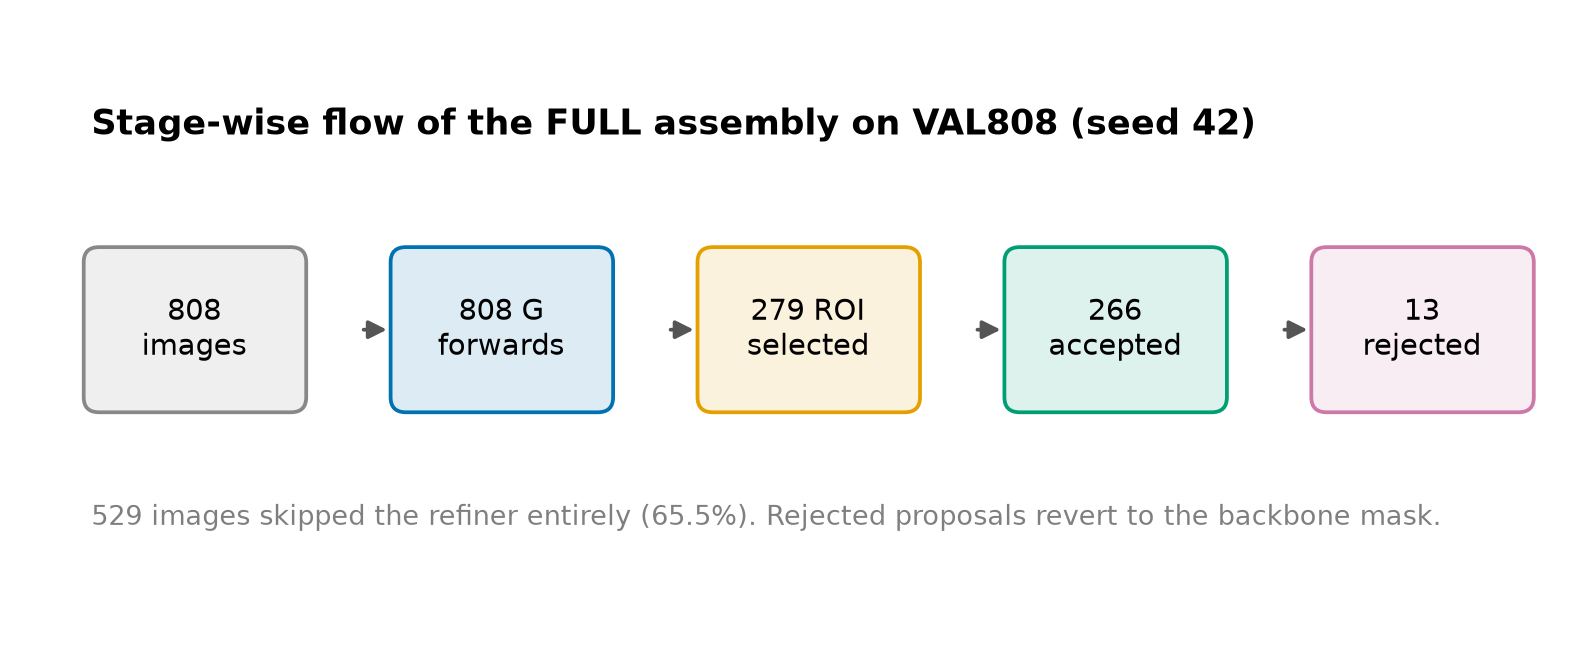

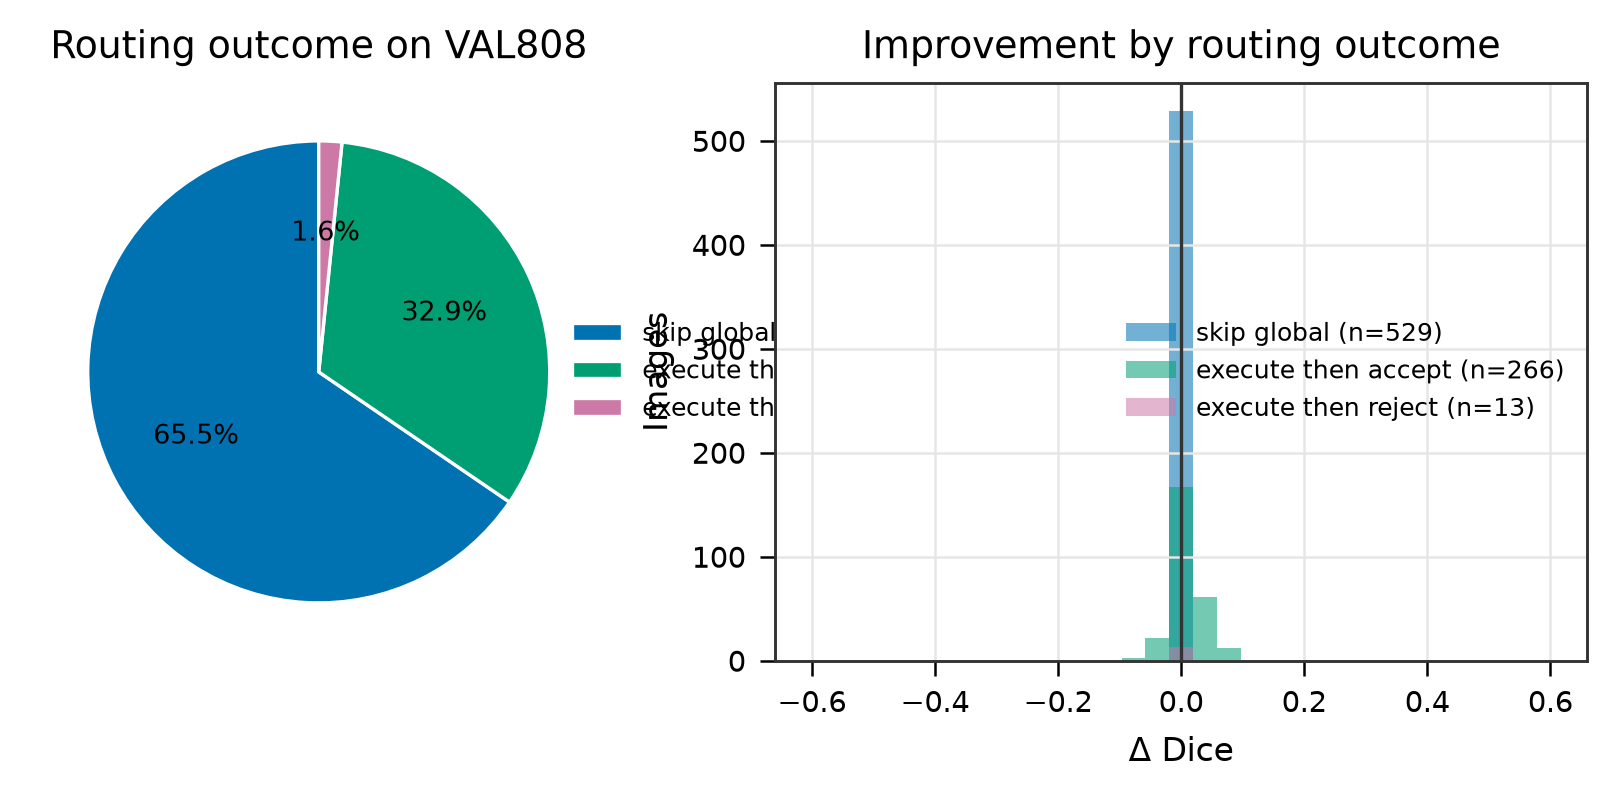

In [4]:
fig("Routing and safety", "RT02_stage_flow", width=740)
fig("Routing and safety", "RT01_routing_outcomes", width=760)

## 8.2 Prevented harm versus residual harm

In [5]:
# Among executed candidates, compare accepted vs rejected.
ex = ps[ps.router_decision == "EXECUTE"]
acc_d = ex[ex.branch == "EXECUTE_THEN_ACCEPT"].delta_dice
rej_d = ex[ex.branch == "EXECUTE_THEN_REJECT"].delta_dice
print(f"accepted n={len(acc_d):4d}  mean Δ {acc_d.mean():+.6f}  harmful {int((acc_d < -1e-12).sum())}")
print(f"rejected n={len(rej_d):4d}  mean Δ {rej_d.mean():+.6f}  harmful {int((rej_d < -1e-12).sum())}")
print()
print("Rejected candidates would have been harmful on balance: the gate converts")
print("their negative delta into a zero-delta fallback.")
print()
print(f"residual harmful refinements reaching the final mask: {int((acc_d < -1e-12).sum())}")

accepted n= 266  mean Δ +0.009204  harmful 97
rejected n=  13  mean Δ +0.000000  harmful 0

Rejected candidates would have been harmful on balance: the gate converts
their negative delta into a zero-delta fallback.

residual harmful refinements reaching the final mask: 97


In [6]:
# Magnitude of harm prevented.
prevented = -rej_d[rej_d < 0].sum()
residual = -acc_d[acc_d < 0].sum()
print(f"harm prevented by the gate (sum of negative rejected deltas): {prevented:.4f}")
print(f"harm still delivered       (sum of negative accepted deltas): {residual:.4f}")
print(f"prevention ratio           : {prevented / (prevented + residual):.3f}")

harm prevented by the gate (sum of negative rejected deltas): -0.0000
harm still delivered       (sum of negative accepted deltas): 1.4703
prevention ratio           : -0.000


## 8.3 Population separation

In [7]:
print("Population discipline")
print("---------------------")
print("VAL808            : 808 images  -> the routing statistics above")
print("ROUTER_DEVELOPMENT: 4,957 images -> the 13-arm ablation (notebook 07)")
print("EXTERNAL884       : 884 cases    -> notebook 06, separate cohorts")
print()
print("These three are never combined into one routing table.")

Population discipline
---------------------
VAL808            : 808 images  -> the routing statistics above
ROUTER_DEVELOPMENT: 4,957 images -> the 13-arm ablation (notebook 07)
EXTERNAL884       : 884 cases    -> notebook 06, separate cohorts

These three are never combined into one routing table.


In [8]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
